<a href="https://colab.research.google.com/github/lucasramosgeo/data-analysis/blob/main/big_query.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import auth
auth.authenticate_user()

In [ ]:
from google.cloud import bigquery

In [ ]:
# Initialize the client
client = bigquery.Client(project="project-884a3481-477a-4199-a13")

In [ ]:
query = """
  SELECT
    id_produto AS produto,
    id_cliente AS cliente,
    EXTRACT(YEAR FROM data) AS ano,
    SUM(quantidade * preco) AS quantidade_total,
    MAX(quantidade * preco) AS quantidade_maxima,
    MIN(quantidade * preco) AS quantidade_minima,
    AVG(quantidade * preco) AS quantidade_media,
    COUNT(*) AS numero_vendas
  FROM `belleza_verde_vendas.vendas`
  GROUP BY
    id_produto,
    id_cliente,
    EXTRACT(YEAR FROM data)
"""

df = client.query(query).to_dataframe()
df.head()


,produto,cliente,ano,quantidade_total,quantidade_maxima,quantidade_minima,quantidade_media,numero_vendas
0,1,1,2021,3443.80,771.00,51.40,382.644444,9
1,1,1,2022,1562.23,377.09,53.87,156.223000,10
2,1,1,2023,776.86,388.43,55.49,129.476667,6
3,2,1,2021,1858.50,398.25,44.25,154.875000,12
4,2,1,2022,1306.76,373.36,46.67,145.195556,9


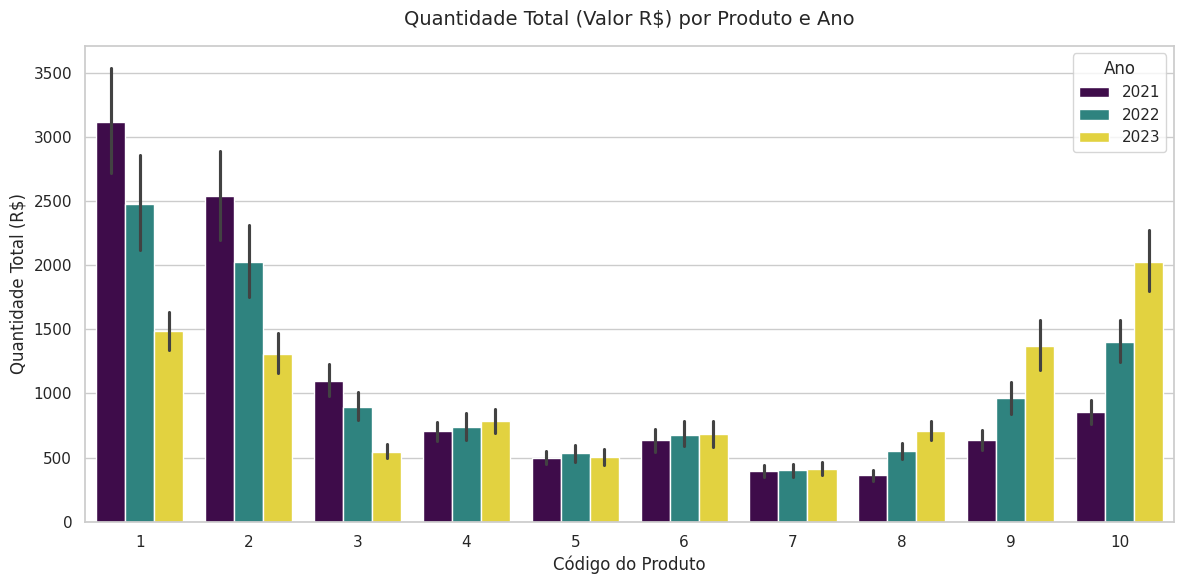

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Agrupando os dados de 'df' diretamente (produto, ano) para somar a quantidade_total
df_agrupado = df.groupby(['produto', 'cliente',
                          'ano'])['quantidade_total'].sum().reset_index()

# Configurar o estilo do gráfico
plt.figure(figsize=(12, 6))
sns.set_theme(style="whitegrid")

# Criar o gráfico de barras diretamente a partir de df_agrupado
ax = sns.barplot(x='produto', y='quantidade_total', hue='ano', data=df_agrupado, palette='viridis')

# Customizar títulos e legendas
plt.title('Quantidade Total (Valor R$) por Produto e Ano', fontsize=14, pad=15)
plt.xlabel('Código do Produto', fontsize=12)
plt.ylabel('Quantidade Total (R$)', fontsize=12)
plt.legend(title='Ano')
plt.tight_layout()

plt.show()

In [ ]:
df.sort_values(by = 'quantidade_maxima', ascending = False)['quantidade_maxima'].head(5)

,quantidade_maxima
661,808.05
721,808.05
361,808.05
571,808.05
271,808.05


In [ ]:
df_numero_vendas_ano = df.groupby(['ano'])['numero_vendas'].sum().reset_index()

ax = sns.

,ano,numero_vendas
0,2021,3650
1,2022,3650
2,2023,3650
